# Lending Club Loan Data Analysis

**Objective:** Build a deep learning model that predicts whether a loan will default, using Lending Club historical data from 2007 to 2015.

**Target:** `not.fully.paid` (1 = loan was not fully paid, 0 = loan was paid)

## 1. Load the Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data/lending_club.csv')

print(df.shape)
print(df.isnull().sum().sum(), "nulls,", df.duplicated().sum(), "duplicates")
df.info()
df.head()

(9578, 14)
0 nulls, 0 duplicates
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9578 entries, 0 to 9577
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   credit.policy      9578 non-null   int64  
 1   purpose            9578 non-null   object 
 2   int.rate           9578 non-null   float64
 3   installment        9578 non-null   float64
 4   log.annual.inc     9578 non-null   float64
 5   dti                9578 non-null   float64
 6   fico               9578 non-null   int64  
 7   days.with.cr.line  9578 non-null   float64
 8   revol.bal          9578 non-null   int64  
 9   revol.util         9578 non-null   float64
 10  inq.last.6mths     9578 non-null   int64  
 11  delinq.2yrs        9578 non-null   int64  
 12  pub.rec            9578 non-null   int64  
 13  not.fully.paid     9578 non-null   int64  
dtypes: float64(6), int64(7), object(1)
memory usage: 1.0+ MB


,credit.policy,purpose,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid
0,1,debt_consolidation,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0
1,1,credit_card,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0
2,1,debt_consolidation,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0
3,1,debt_consolidation,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0
4,1,credit_card,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0


## 2. Feature Transformation

**Task 1: Transform categorical values into numerical values.**

The dataset has 14 columns, and 13 of them are already numeric. The only categorical column is `purpose`, which describes what the loan is for.

Note: the assignment lists six values for `purpose`, but the data contains seven. The unlisted one is `home_improvement`.

I use one-hot encoding rather than label encoding because `purpose` has no natural order. Numbering the categories 0 through 6 would suggest to the model that `small_business` is somehow "greater than" `credit_card`, which is meaningless. One-hot encoding gives each category its own 0/1 column instead.

I also set `drop_first=True`, which drops the first category (`all_other`) and makes it the baseline. A row with zeros in all six `purpose_` columns represents `all_other`. This avoids a redundant column, since seven categories can be fully described by six columns.

In [2]:
print(df['purpose'].value_counts())

df_encoded = pd.get_dummies(df, columns=['purpose'], drop_first=True, dtype=int)

print(df_encoded.shape)
df_encoded.head()

purpose
debt_consolidation    3957
all_other             2331
credit_card           1262
home_improvement       629
small_business         619
major_purchase         437
educational            343
Name: count, dtype: int64
(9578, 19)


,credit.policy,int.rate,installment,log.annual.inc,dti,fico,days.with.cr.line,revol.bal,revol.util,inq.last.6mths,delinq.2yrs,pub.rec,not.fully.paid,purpose_credit_card,purpose_debt_consolidation,purpose_educational,purpose_home_improvement,purpose_major_purchase,purpose_small_business
0,1,0.1189,829.10,11.350407,19.48,737,5639.958333,28854,52.1,0,0,0,0,0,1,0,0,0,0
1,1,0.1071,228.22,11.082143,14.29,707,2760.000000,33623,76.7,0,0,0,0,1,0,0,0,0,0
2,1,0.1357,366.86,10.373491,11.63,682,4710.000000,3511,25.6,1,0,0,0,0,1,0,0,0,0
3,1,0.1008,162.34,11.350407,8.10,712,2699.958333,33667,73.2,1,0,0,0,0,1,0,0,0,0
4,1,0.1426,102.92,11.299732,14.97,667,4066.000000,4740,39.5,0,1,0,0,1,0,0,0,0,0


In [3]:
print(df.shape)
print(df.columns.tolist()[:5])

(9578, 14)
['credit.policy', 'purpose', 'int.rate', 'installment', 'log.annual.inc']


## 3. Exploratory Data Analysis

**Task 2: Explore the different factors in the dataset.**

I start with the target variable, since the assignment notes the data is highly imbalanced, then look at how default rates vary across loan purposes.

Fully paid (0):     8,045  (83.99%)
Not fully paid (1): 1,533  (16.01%)


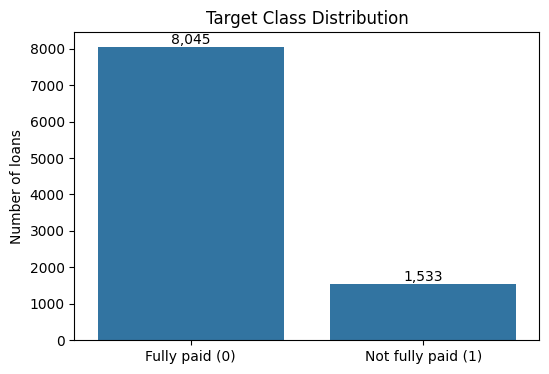

In [4]:
counts = df['not.fully.paid'].value_counts()
pct = df['not.fully.paid'].value_counts(normalize=True) * 100

print(f"Fully paid (0):     {counts[0]:,}  ({pct[0]:.2f}%)")
print(f"Not fully paid (1): {counts[1]:,}  ({pct[1]:.2f}%)")

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x='not.fully.paid')
ax.set_xticks([0, 1])
ax.set_xticklabels(['Fully paid (0)', 'Not fully paid (1)'])
ax.set_title('Target Class Distribution')
ax.set_xlabel('')
ax.set_ylabel('Number of loans')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')
plt.show()

                    default_rate  loans
purpose                                
small_business              27.8    619
educational                 20.1    343
home_improvement            17.0    629
all_other                   16.6   2331
debt_consolidation          15.2   3957
credit_card                 11.6   1262
major_purchase              11.2    437


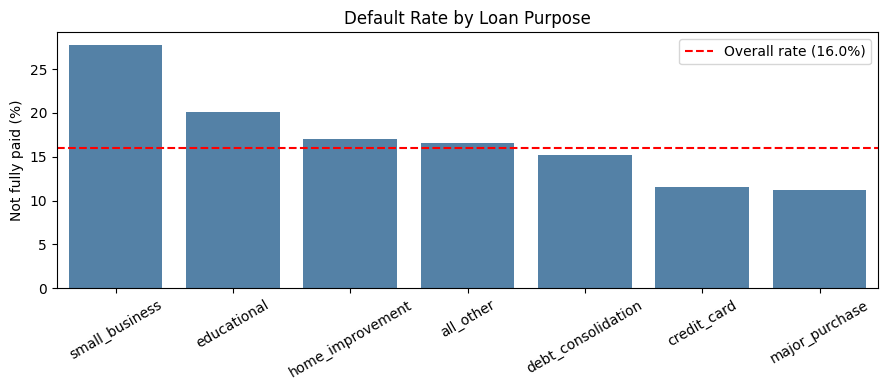

In [5]:
purpose_stats = (df.groupby('purpose')['not.fully.paid']
                   .agg(default_rate='mean', loans='count')
                   .sort_values('default_rate', ascending=False))
purpose_stats['default_rate'] = (purpose_stats['default_rate'] * 100).round(1)
print(purpose_stats)

plt.figure(figsize=(9, 4))
ax = sns.barplot(x=purpose_stats.index, y=purpose_stats['default_rate'], color='steelblue')
ax.axhline(df['not.fully.paid'].mean() * 100, color='red', linestyle='--', label='Overall rate (16.0%)')
ax.set_title('Default Rate by Loan Purpose')
ax.set_xlabel('')
ax.set_ylabel('Not fully paid (%)')
ax.tick_params(axis='x', rotation=30)
ax.legend()
plt.tight_layout()
plt.show()

In [6]:
group_means = (df.drop(columns='purpose')
                 .groupby('not.fully.paid')
                 .mean()
                 .T
                 .round(3))
group_means.columns = ['Fully paid (0)', 'Not fully paid (1)']
group_means

,Fully paid (0),Not fully paid (1)
credit.policy,0.832,0.661
int.rate,0.121,0.132
installment,314.574,342.785
log.annual.inc,10.941,10.885
dti,12.494,13.196
fico,713.327,697.828
days.with.cr.line,4592.633,4393.541
revol.bal,16122.724,21066.294
revol.util,45.760,52.255
inq.last.6mths,1.434,2.331


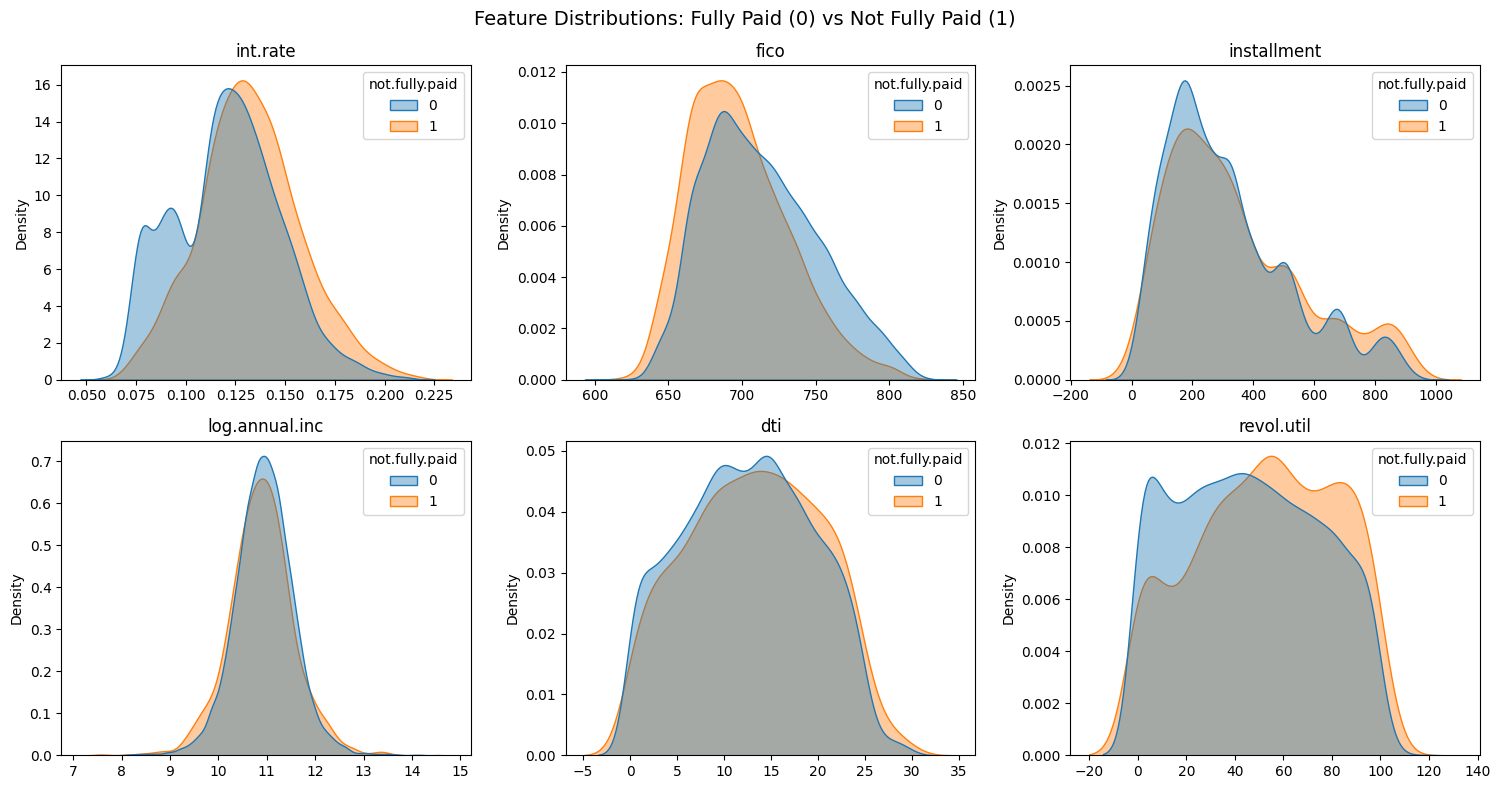

In [7]:
features = ['int.rate', 'fico', 'installment', 'log.annual.inc', 'dti', 'revol.util']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), features):
    sns.kdeplot(data=df, x=col, hue='not.fully.paid',
                common_norm=False, fill=True, alpha=0.4, ax=ax)
    ax.set_title(col)
    ax.set_xlabel('')
plt.suptitle('Feature Distributions: Fully Paid (0) vs Not Fully Paid (1)', fontsize=14)
plt.tight_layout()
plt.show()

**Observations:**

- Borrowers who did not fully pay had, on average, lower FICO scores (698 vs 713), higher interest rates (13.2% vs 12.1%), higher revolving utilization (52% vs 46%), and more credit inquiries in the last six months (2.3 vs 1.4).
- Only 66% of defaulted loans met Lending Club's credit policy, compared to 83% of fully paid loans.
- The distributions for the two groups overlap heavily on every feature. FICO and interest rate show the clearest shift, while installment, income, and debt-to-income look nearly identical between groups.
- Because no single feature separates the classes well, the model will need to combine many weak signals, and performance should be judged with that in mind.

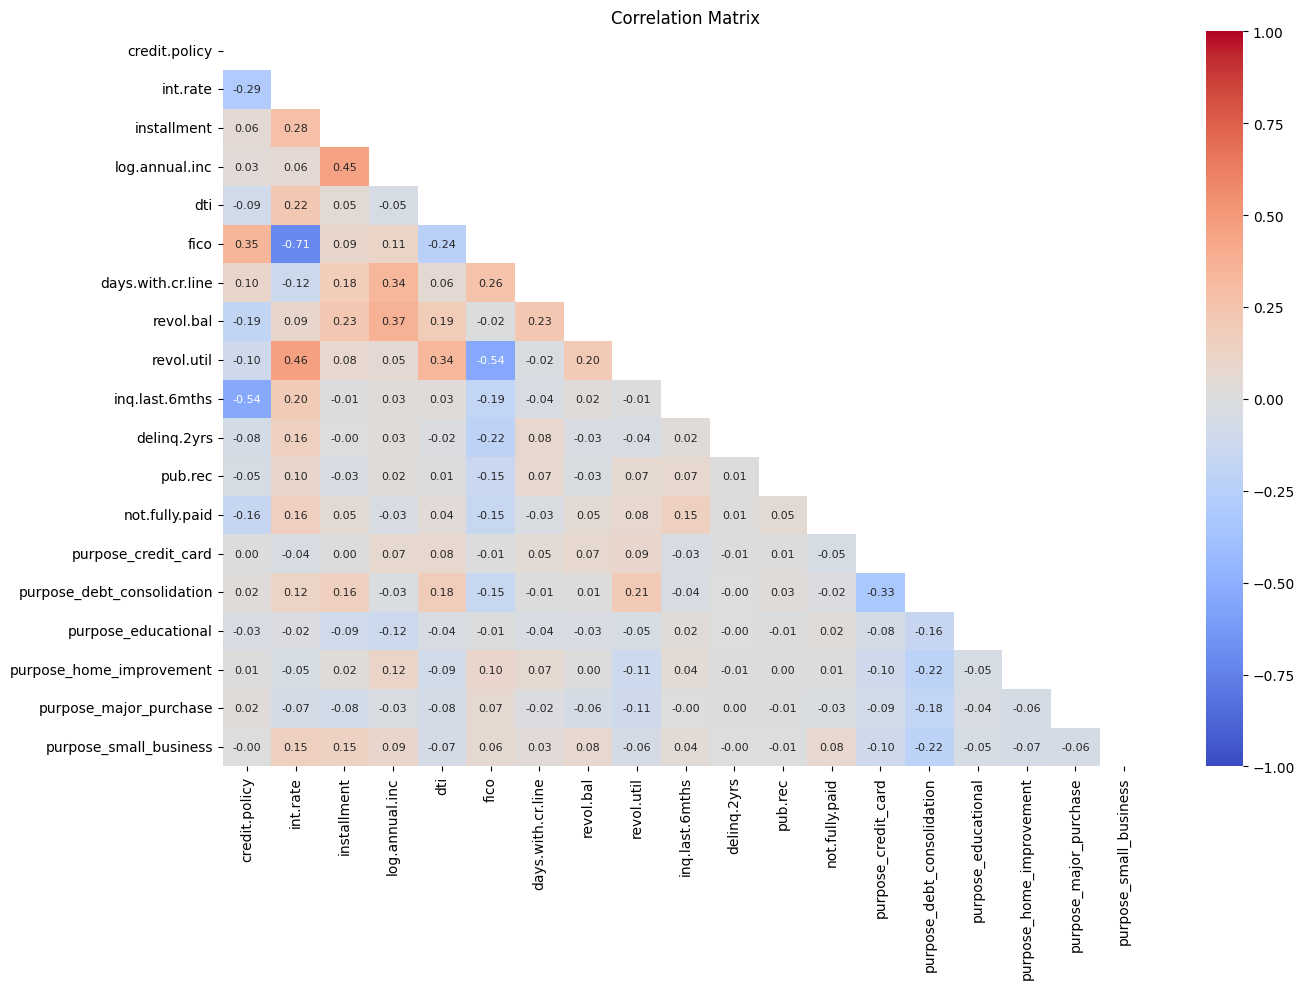

Correlation with target:
int.rate                      0.160
credit.policy                -0.158
fico                         -0.150
inq.last.6mths                0.149
purpose_small_business        0.084
revol.util                    0.082
revol.bal                     0.054
installment                   0.050
pub.rec                       0.049
purpose_credit_card          -0.047
dti                           0.037
log.annual.inc               -0.033
days.with.cr.line            -0.029
purpose_major_purchase       -0.029
purpose_educational           0.022
purpose_debt_consolidation   -0.018
delinq.2yrs                   0.009
purpose_home_improvement      0.007
Name: not.fully.paid, dtype: float64


In [8]:
corr = df_encoded.corr()

plt.figure(figsize=(14, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1, annot_kws={'size': 8})
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

print("Correlation with target:")
print(corr['not.fully.paid'].drop('not.fully.paid')
      .sort_values(key=abs, ascending=False).round(3))

## 4. Additional Feature Engineering

**Task 3: Check the correlation between features and drop those with a strong correlation.**

Two features that are strongly correlated carry mostly the same information. Keeping both adds redundancy without adding signal. I use an absolute correlation of 0.7 as the threshold for "strong."

In [9]:
threshold = 0.7

feature_corr = df_encoded.drop(columns='not.fully.paid').corr()
upper = feature_corr.where(np.triu(np.ones(feature_corr.shape, dtype=bool), k=1))

pairs = upper.stack()
high_pairs = pairs[pairs.abs() > threshold]
print("Feature pairs above threshold:")
print(high_pairs.round(3))

df_model = df_encoded.drop(columns=['fico'])
print("\nShape after dropping:", df_model.shape)

Feature pairs above threshold:
int.rate  fico   -0.715
dtype: float64

Shape after dropping: (9578, 18)


**Result:** Only one pair of features exceeded the 0.7 threshold: `int.rate` and `fico` (-0.715). This relationship is expected, since Lending Club assigns interest rates largely based on credit score. I dropped `fico` and kept `int.rate` because the interest rate has a slightly stronger correlation with the target (0.160 vs 0.150) and reflects Lending Club's overall risk assessment, which already incorporates the FICO score. The dataset now has 17 features plus the target.

No feature has a strong linear relationship with the target on its own (the highest is 0.16), which is consistent with the overlapping distributions seen in the EDA.

## 5. Data Preparation for Modeling

Before training, the data needs three things:

1. **A train / validation / test split.** The model learns from the training set, the validation set is used to monitor for overfitting during training, and the test set is held back until the very end for an honest evaluation.
2. **Feature scaling.** Neural networks train poorly when features are on very different scales (for example, `revol.bal` is in the tens of thousands while `int.rate` is around 0.12).
3. **Handling class imbalance.** Only 16% of loans are in the "not fully paid" class, so without correction the model would learn to predict "fully paid" for everyone.

In [10]:
from sklearn.model_selection import train_test_split

X = df_model.drop(columns='not.fully.paid')
y = df_model['not.fully.paid']

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.2, stratify=y_temp, random_state=42)

for name, Xs, ys in [('Train', X_train, y_train), ('Validation', X_val, y_val), ('Test', X_test, y_test)]:
    print(f"{name:<11} {Xs.shape}  default rate: {ys.mean() * 100:.2f}%")

Train       (6129, 17)  default rate: 16.01%
Validation  (1533, 17)  default rate: 15.98%
Test        (1916, 17)  default rate: 16.02%


In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

weights = compute_class_weight('balanced', classes=np.array([0, 1]), y=y_train)
class_weights = {0: weights[0], 1: weights[1]}
print("Class weights:", {k: round(v, 3) for k, v in class_weights.items()})

Class weights: {0: np.float64(0.595), 1: np.float64(3.124)}


**Result:** The data was split into 6,129 training, 1,533 validation, and 1,916 test rows, stratified so each set keeps the same 16% default rate. Features were standardized using statistics from the training set only, to avoid data leakage.

To address the class imbalance, I use class weights during training rather than resampling. Errors on the minority class (not fully paid) are weighted about 3.1, and errors on the majority class about 0.6, giving both classes equal overall influence on the loss. This leaves the validation and test sets at their natural class distribution for a realistic evaluation.

## 6. Modeling

**Task 4: Build a deep learning model using Keras with a TensorFlow backend.**

The model is a small feedforward neural network: two hidden layers with ReLU activation, dropout after each to reduce overfitting, and a single sigmoid output that gives the predicted probability that a loan will not be fully paid.

I kept the network small on purpose. With only about 6,100 training rows and 17 features, a large network would memorize the training data rather than learn patterns that generalize.

In [12]:
import os
os.environ['TF_USE_LEGACY_KERAS'] = '0'

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)

model = keras.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(16, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=[keras.metrics.AUC(name='auc'), keras.metrics.Recall(name='recall')],
    jit_compile=False
)

model.summary()

I0000 00:00:1790907062.288137  299422 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790907063.052459  299422 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
W0000 00:00:1790907063.329272  299422 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1790907063.333799  299422 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which cou

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,121 (4.38 KB)

 Trainable params: 1,121 (4.38 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_auc', mode='max', patience=10, restore_best_weights=True)

history = model.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=64,
    class_weight=class_weights,
    callbacks=[early_stop],
    verbose=2
)

print(f"\nStopped after {len(history.history['loss'])} epochs")
print(f"Best validation AUC: {max(history.history['val_auc']):.4f}")

Epoch 1/100


W0000 00:00:1790907068.235685  299970 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1790907068.236703  299969 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1790907068.237844  299971 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1790907068.239188  299961 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1790907068.239862  299974 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1790907068.240933  299965 gpu_kernel_to_blob_pass.cc:190] Failed to compile generated PTX with ptxas. Falling back to compilation by driver.
W0000 00:00:1790907068.242287  299963 gpu_kernel_to_blob_pass.cc:190] Failed to co

96/96 - 21s - 214ms/step - auc: 0.5377 - loss: 0.7238 - recall: 0.4883 - val_auc: 0.6136 - val_loss: 0.7013 - val_recall: 0.5918
Epoch 2/100
96/96 - 0s - 3ms/step - auc: 0.5944 - loss: 0.6900 - recall: 0.5535 - val_auc: 0.6429 - val_loss: 0.6772 - val_recall: 0.5878
Epoch 3/100
96/96 - 0s - 3ms/step - auc: 0.6247 - loss: 0.6738 - recall: 0.5749 - val_auc: 0.6542 - val_loss: 0.6643 - val_recall: 0.5878
Epoch 4/100
96/96 - 0s - 3ms/step - auc: 0.6424 - loss: 0.6620 - recall: 0.5708 - val_auc: 0.6602 - val_loss: 0.6559 - val_recall: 0.5755
Epoch 5/100
96/96 - 0s - 3ms/step - auc: 0.6531 - loss: 0.6554 - recall: 0.5790 - val_auc: 0.6652 - val_loss: 0.6485 - val_recall: 0.5755
Epoch 6/100
96/96 - 0s - 3ms/step - auc: 0.6558 - loss: 0.6548 - recall: 0.5831 - val_auc: 0.6668 - val_loss: 0.6464 - val_recall: 0.5837
Epoch 7/100
96/96 - 0s - 4ms/step - auc: 0.6524 - loss: 0.6560 - recall: 0.5607 - val_auc: 0.6680 - val_loss: 0.6462 - val_recall: 0.5755
Epoch 8/100
96/96 - 0s - 3ms/step - auc: 0.

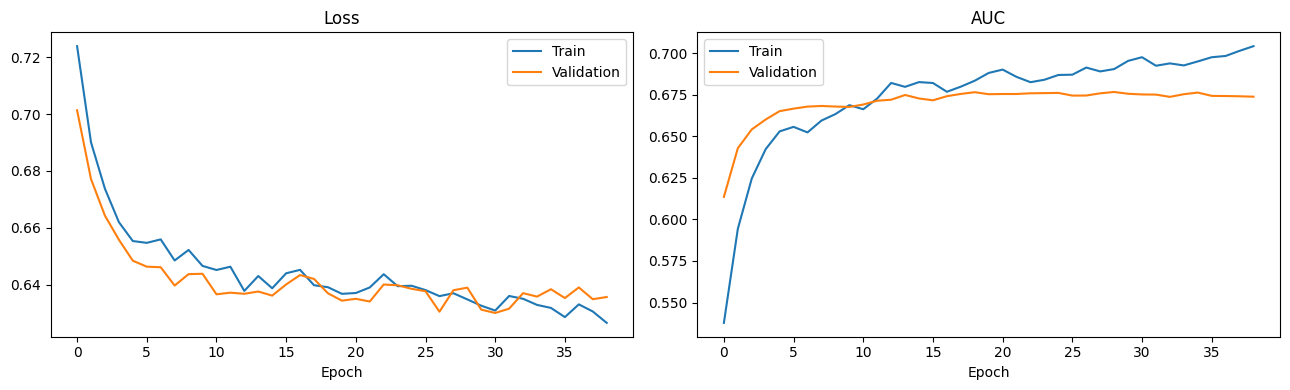

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history.history['loss'], label='Train')
axes[0].plot(history.history['val_loss'], label='Validation')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(history.history['auc'], label='Train')
axes[1].plot(history.history['val_auc'], label='Validation')
axes[1].set_title('AUC')
axes[1].set_xlabel('Epoch')
axes[1].legend()

plt.tight_layout()
plt.show()

## 7. Evaluation

The test set has not been used at any point during training or tuning, so these results reflect how the model would perform on new loans. Because the data is imbalanced, I focus on sensitivity (recall) and ROC AUC rather than accuracy.

Sensitivity (recall): 0.567
Specificity:          0.674
ROC AUC:              0.680

                precision    recall  f1-score   support

    Fully paid       0.89      0.67      0.77      1609
Not fully paid       0.25      0.57      0.35       307

      accuracy                           0.66      1916
     macro avg       0.57      0.62      0.56      1916
  weighted avg       0.79      0.66      0.70      1916



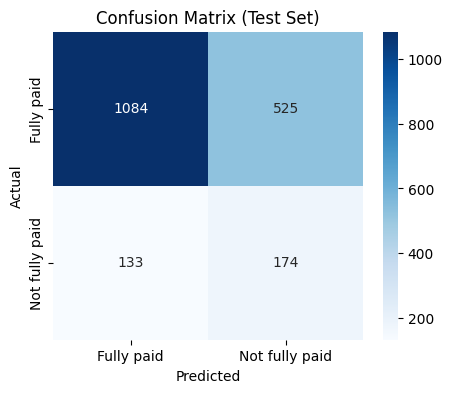

In [15]:
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, recall_score

y_prob = model.predict(X_test_scaled, verbose=0).ravel()
y_pred = (y_prob > 0.5).astype(int)

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print(f"Sensitivity (recall): {tp / (tp + fn):.3f}")
print(f"Specificity:          {tn / (tn + fp):.3f}")
print(f"ROC AUC:              {roc_auc_score(y_test, y_prob):.3f}\n")
print(classification_report(y_test, y_pred, target_names=['Fully paid', 'Not fully paid']))

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Fully paid', 'Not fully paid'],
            yticklabels=['Fully paid', 'Not fully paid'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (Test Set)')
plt.show()

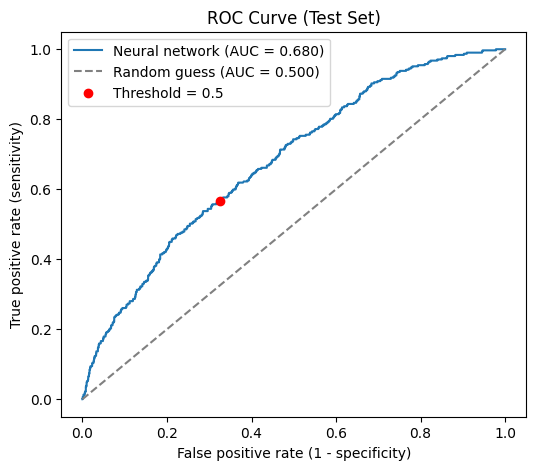

In [16]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'Neural network (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess (AUC = 0.500)')
plt.scatter(fp / (fp + tn), tp / (tp + fn), color='red', zorder=5, label='Threshold = 0.5')
plt.xlabel('False positive rate (1 - specificity)')
plt.ylabel('True positive rate (sensitivity)')
plt.title('ROC Curve (Test Set)')
plt.legend()
plt.show()

## 8. Conclusion

**Summary of the approach**

- **Feature transformation:** The one categorical column, `purpose`, was one-hot encoded into six binary columns.
- **EDA:** The target is imbalanced, with 16% of loans not fully paid. Default rates vary by purpose, from 11% for major purchases to 28% for small business loans. Defaulted loans tend to have lower FICO scores, higher interest rates, and more recent credit inquiries, but the two classes overlap heavily on every feature.
- **Feature engineering:** `int.rate` and `fico` were strongly correlated (-0.715), so `fico` was dropped, leaving 17 features.
- **Modeling:** A feedforward neural network (two hidden layers of 32 and 16 neurons, dropout of 0.3, sigmoid output) was trained with class weights to handle the imbalance and early stopping to limit overfitting.

**Results on the test set**

| Metric | Value |
|---|---|
| Sensitivity (recall) | 0.567 |
| Specificity | 0.674|
| ROC AUC | 0.680|

**Interpretation**

The model identifies about 57% of loans that go on to default, compared to 0% for a baseline that predicts every loan will be paid. That baseline would score 84% accuracy while being useless for the actual goal, which is why sensitivity and AUC are the more meaningful metrics here.

The trade-off is a high number of false positives: most loans the model flags are in fact repaid. In practice, a lender would choose the probability threshold based on costs. If a missed default is much more expensive than declining or reviewing a good loan, a lower threshold that catches more defaults is justified.

The ROC AUC of 0.680 shows the model performs meaningfully better than chance but is far from perfect. This is consistent with the EDA, where no single feature separated the classes well and the strongest correlation with the target was only 0.16. The limit is in the data rather than the model: the available features describe the borrower at the time of application and do not capture later events, such as job loss or medical expenses, that often drive default.

**Possible improvements**

- Tune the decision threshold to match a specific business cost for false negatives versus false positives.
- Engineer additional features, such as the ratio of installment to income.
- Compare against tree-based models such as gradient boosting, which often perform as well as or better than neural networks on small tabular datasets.